<a href="https://colab.research.google.com/github/Lourdes-Churacutipa/Repositorio-de-lourdes/blob/main/Tarea9_Lab9_3_LSTM_Piura_Tambogrande.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 9_3 (extensión) · LSTM para el río Piura en **TAMBOGRANDE** (CAMELS-PE)
## Ciencia de Datos Ambientales – Aplicado al Perú

En el Lab 9_3 entrenaste una RNN y una LSTM con **una sola cuenca** (Huatiapa, río Majes). Aquí repetimos **el mismo pipeline** en otra cuenca, la del **río Piura en Tambogrande**, para responder una pregunta concreta:

> ¿La ventaja de la LSTM sobre el modelo hidrológico (PISCO-ARNOVIC) y sobre la persistencia es una propiedad del método, o fue una particularidad de Huatiapa?

### Qué hace este notebook
1. Descarga **CAMELS-PE** desde Zenodo (solo extrae lo necesario) y **busca la estación Tambogrande por nombre**.
2. Revisa la **cobertura de caudal observado** y elige los periodos de entrenamiento/validación/prueba (los del Lab 9_3 si hay datos suficientes; si no, unos automáticos).
3. Corre `correr_cuenca(gauge_id)`: **A1** (simulación solo con meteorología) y **A2** (pronóstico a 1, 3 y 7 días con el caudal observado), con **3 semillas** y comparando contra **climatología, persistencia y PISCO-ARNOVIC**.
4. Compara con Huatiapa y exporta caudales mensuales y por temporada (dic–may) por si los quieres usar en tu **proyecto ENSO–Piura** (te da el indicador de caudal).

### Qué cambia respecto a Huatiapa (y por qué importa)
| | Huatiapa (Majes) | Tambogrande (Piura) |
|---|---|---|
| Vertiente | Pacífico, altoandina, con embalses y riego | Pacífico norte, régimen muy ligado a El Niño |
| Qué esperar *(verifícalo con tus datos)* | crecidas ene–mar, estiaje largo | caudales muy bajos casi todo el año y crecidas violentas en años Niño (1983, 1998, 2017) |
| Reto para la red | memoria larga | **eventos extremos raros**: el NSE lo dominan unos pocos picos |

⏱️ Tiempo aproximado: **unos 10 min de entrenamiento** en CPU de Colab, más la descarga del zip (depende de su tamaño). No necesitas GPU.

**Cómo usarlo:** `Entorno de ejecución → Ejecutar todo`. Lo único que normalmente tocarás es la celda de configuración.

In [13]:
# ======================= CONFIGURACIÓN =======================
NOMBRE_ESTACION = 'TAMBOGRANDE'   # texto a buscar en stations.csv (ignora mayúsculas y tildes)
GAUGE_ID_MANUAL = None            # si ya conoces el ID (p. ej. 'PE_xxxxxx') escríbelo aquí y se omite la búsqueda
ZENODO_RECORD   = '21195425'      # CAMELS-PE v1.0.1  (DOI 10.5281/zenodo.21195425)
DATA_DIR        = 'camels_pe'     # carpeta local de trabajo
RUTAS_EXTRA     = []              # p. ej. ['/content/drive/MyDrive/CAMELS-PE'] si ya tienes el dataset descomprimido

# Periodos cronológicos (los mismos del Lab 9_3, para poder comparar con Huatiapa)
PERIODOS_LAB = {'ini_entrena': '1998-01-01', 'fin_entrena': '2010-12-31',
                'fin_valida': '2015-12-31',  'fin_prueba': '2020-12-31'}   # 2020 = último año con temperatura PISCOt
MIN_DIAS_OBS = {'entrena': 730, 'valida': 180, 'prueba': 365}              # mínimo de días con caudal observado por periodo

VARS_MET     = ['prec', 'tmean', 'tmax', 'tmin', 'srad', 'vprp']
VENTANA_SIM  = 180                # A1: días de meteorología que ve el modelo
VENTANA_PRON = 90                 # A2: días de meteorología + caudal
HORIZONTES   = [1, 3, 7]          # A2: días hacia adelante
N_SEMILLAS   = 3                  # ensamble: más semillas = resultados más estables (y más lento)
EPOCAS       = 40
EPS_LOG      = None               # offset del log(caudal + eps). None = automático (10 % de la mediana del caudal observado)

CORRER_SENSIBILIDAD     = False   # True = prueba ventanas de 30/90/180/365 días (tarda varios minutos más)
COMPARAR_CON_HUATIAPA   = False   # True = vuelve a correr Huatiapa con ESTE mismo código (comparación exacta; ~el doble de tiempo)
EXPORTAR_PARA_PROYECTO  = True    # guarda caudal mensual y por temporada dic–may en CSV
MIN_FRAC_EXPORT         = 0.8     # fracción mínima de días con caudal observado para aceptar un mes o una temporada

In [14]:
import os, sys, time, zipfile, subprocess, unicodedata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from IPython.display import display

warnings.filterwarnings('ignore', category=FutureWarning)
try:
    import tensorflow as tf
except ImportError:                       # Colab ya lo trae; esto es solo por si acaso
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'tensorflow'], check=True)
    import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

plt.rcParams['figure.dpi'] = 100
os.makedirs(DATA_DIR, exist_ok=True)
print('TensorFlow', tf.__version__, '| GPU:', bool(tf.config.list_physical_devices('GPU')))

TensorFlow 2.21.0 | GPU: False


# 1. Datos: descargar CAMELS-PE y encontrar la estación

CAMELS-PE (SENAMHI) reúne **136 cuencas** con series diarias 1981–2025: lluvia media de cuenca (PISCOp), temperaturas (PISCOt, hasta 2020), radiación y vapor (ERA5-Land), **caudal observado** (`flow_obs`) y **caudal simulado** por PISCO-ARNOVIC (`flow_sim`), todo en mm/día.

Las funciones de abajo buscan primero el archivo en tu carpeta local (`DATA_DIR` o `RUTAS_EXTRA`) y solo si no está lo descargan de Zenodo y **extraen únicamente** `stations.csv` y el CSV de la estación, sin descomprimir todo.

In [15]:
def _norm(s):
    """minúsculas y sin tildes, para buscar nombres de forma robusta"""
    return unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().lower()

def localizar(basename, preferir=()):
    """Busca un archivo por nombre en DATA_DIR y RUTAS_EXTRA."""
    hallados = []
    for base in [DATA_DIR] + list(RUTAS_EXTRA):
        for raiz, _, archivos in os.walk(base):
            if basename in archivos:
                hallados.append(os.path.join(raiz, basename))
    if not hallados:
        return None
    for kw in preferir:
        for h in hallados:
            if kw in h.lower():
                return h
    return hallados[0]

def descargar_zenodo(record=ZENODO_RECORD, destino=DATA_DIR):
    """Descarga el zip de CAMELS-PE desde Zenodo (si no existe ya en destino)."""
    ya = [f for f in os.listdir(destino) if f.lower().endswith('.zip')]
    if ya:
        return os.path.join(destino, ya[0])
    info = requests.get(f'https://zenodo.org/api/records/{record}', timeout=60)
    info.raise_for_status()
    archivos = info.json().get('files', [])
    print('Archivos del registro de Zenodo:')
    for f in archivos:
        print(f"  {f.get('key') or f.get('filename')}  ({f.get('size', 0) / 1e6:.0f} MB)")
    zips = [f for f in archivos if (f.get('key') or f.get('filename') or '').lower().endswith('.zip')]
    if not zips:
        raise RuntimeError('El registro no trae un .zip. Descarga CAMELS-PE manualmente, descomprímelo y pon su ruta en RUTAS_EXTRA.')
    f = max(zips, key=lambda x: x.get('size', 0))
    nombre = f.get('key') or f.get('filename')
    enlaces = f.get('links', {})
    url = enlaces.get('self') or enlaces.get('download') or f'https://zenodo.org/records/{record}/files/{nombre}?download=1'
    ruta = os.path.join(destino, nombre)
    print(f'Descargando {nombre} ...')
    with requests.get(url, stream=True, timeout=120) as r:
        r.raise_for_status()
        total, bajado = int(r.headers.get('content-length', 0)), 0
        with open(ruta, 'wb') as out:
            for trozo in r.iter_content(chunk_size=1 << 20):
                out.write(trozo)
                bajado += len(trozo)
                if bajado % (50 << 20) < (1 << 20):
                    print(f'  {bajado / 1e6:.0f} / {total / 1e6:.0f} MB')
    return ruta

def extraer_del_zip(ruta_zip, basename, preferir=()):
    """Extrae de un zip solo el archivo 'basename' (si hay varios, prefiere rutas con las palabras de 'preferir')."""
    with zipfile.ZipFile(ruta_zip) as z:
        cand = [n for n in z.namelist()
                if os.path.basename(n) == basename and not n.endswith('/') and '__MACOSX' not in n]
        if not cand:
            return None
        elegido = next((n for kw in preferir for n in cand if kw in n.lower()), cand[0])
        destino = os.path.join(DATA_DIR, basename)
        with z.open(elegido) as src, open(destino, 'wb') as dst:
            dst.write(src.read())
    return destino

_ZIP = {'ruta': None}
def asegurar(basename, preferir=()):
    """Devuelve la ruta local de un archivo de CAMELS-PE, descargándolo/extrayéndolo si hace falta."""
    ruta = localizar(basename, preferir)
    if ruta:
        return ruta
    if _ZIP['ruta'] is None:
        _ZIP['ruta'] = descargar_zenodo()
    ruta = extraer_del_zip(_ZIP['ruta'], basename, preferir)
    if ruta is None:
        with zipfile.ZipFile(_ZIP['ruta']) as z:
            muestra = [n for n in z.namelist() if not n.endswith('/')][:40]
        raise FileNotFoundError(f'No encontré {basename} dentro del zip. Primeros archivos del zip:\n  ' + '\n  '.join(muestra))
    return ruta

In [16]:
# ---- Buscar la estación en stations.csv ----
stations = pd.read_csv(asegurar('stations.csv', preferir=('metadata',)), sep=None, engine='python')
col_id = 'gauge_id' if 'gauge_id' in stations.columns else stations.columns[0]
cols_texto = [c for c in stations.columns if not pd.api.types.is_numeric_dtype(stations[c])]   # columnas de texto (robusto entre versiones de pandas)
print(f'stations.csv: {len(stations)} estaciones | columnas: {list(stations.columns)}')

def buscar(texto):
    t = _norm(texto)
    m = stations[cols_texto].apply(lambda s: s.map(_norm).str.contains(t, regex=False)).any(axis=1)
    return stations[m]

def cercanas(lat, lon, k=8):
    """Estaciones más cercanas a un punto (si stations.csv trae coordenadas)."""
    clat = next((c for c in stations.columns if 'lat' in c.lower()), None)
    clon = next((c for c in stations.columns if 'lon' in c.lower()), None)
    if not clat or not clon:
        return None
    d = np.hypot(stations[clat] - lat, (stations[clon] - lon) * np.cos(np.radians(lat)))
    return stations.assign(dist_grados=d.round(3)).nsmallest(k, 'dist_grados')

if GAUGE_ID_MANUAL:
    GAUGE = GAUGE_ID_MANUAL
    fila = stations[stations[col_id] == GAUGE]
else:
    cand = buscar(NOMBRE_ESTACION)
    if len(cand) == 0:
        print(f'No encontré "{NOMBRE_ESTACION}". Estaciones que contienen "piura" o "tambo":')
        display(pd.concat([buscar('piura'), buscar('tambo')]).drop_duplicates())
        cerca = cercanas(-4.93, -80.34)          # coordenadas aproximadas de Tambogrande
        if cerca is not None:
            print('Estaciones más cercanas a Tambogrande (aprox.):')
            display(cerca)
        raise ValueError('Estación no encontrada: revisa las tablas de arriba y escribe el ID en GAUGE_ID_MANUAL.')
    if len(cand) > 1:
        print('Hay varias coincidencias; uso la primera. Si no es la correcta, escribe el ID en GAUGE_ID_MANUAL:')
        display(cand)
    GAUGE = cand.iloc[0][col_id]
    fila = cand.iloc[[0]]

print(f'\nEstación seleccionada: {GAUGE}')
display(fila.T)

stations.csv: 136 estaciones | columnas: ['gauge_id', 'gauge_name', 'gauge_region', 'gauge_lat', 'gauge_lon', 'gauge_elev', 'gauge_record_start', 'gauge_record_end', 'gauge_perc_obs', 'name_cat', 'is_nested', 'nested_group_id', 'nested_group_size', 'downstream_gauge_id', 'upstream_gauge_id']

Estación seleccionada: PE_47E0522C


,33
gauge_id,PE_47E0522C
gauge_name,Tambogrande
gauge_region,Pacific
gauge_lat,-4.938
gauge_lon,-80.344
gauge_elev,59
gauge_record_start,2014-12-21
gauge_record_end,2025-04-12
gauge_perc_obs,10.91
name_cat,Cuenca Piura


Periodo: 1981-01-01 a 2025-12-31  (16436 días)
Días con caudal observado: 1793 (11%)  |  primero: 2014-12-21  último: 2025-04-12
Caudal observado (mm/d): mediana 0.300 | P95 5.208 | máximo 22.44 el 2017-03-11 | días en cero: 2


,count,mean,std,min,25%,50%,75%,max
prec,16436.0,1.64,4.95,0.00,0.02,0.15,0.98,102.26
prec_var,16436.0,8.32,51.22,0.00,0.00,0.06,1.33,3135.80
flow_obs,1793.0,1.08,2.29,0.00,0.09,0.30,0.89,22.44
flow_sim,16436.0,0.63,1.71,0.00,0.06,0.15,0.54,22.44
pet,13149.0,4.21,0.65,2.28,3.74,4.20,4.70,5.92
tmin,14610.0,17.34,1.83,11.93,15.90,17.19,18.86,21.97
tmean,14610.0,22.51,1.37,18.05,21.45,22.48,23.58,26.40
tmax,14610.0,27.68,1.30,21.38,26.85,27.74,28.59,32.04
srad,16436.0,16.76,2.97,2.94,15.10,17.05,18.76,25.00
vprp,16436.0,18.53,2.42,11.25,16.59,18.08,20.26,26.03


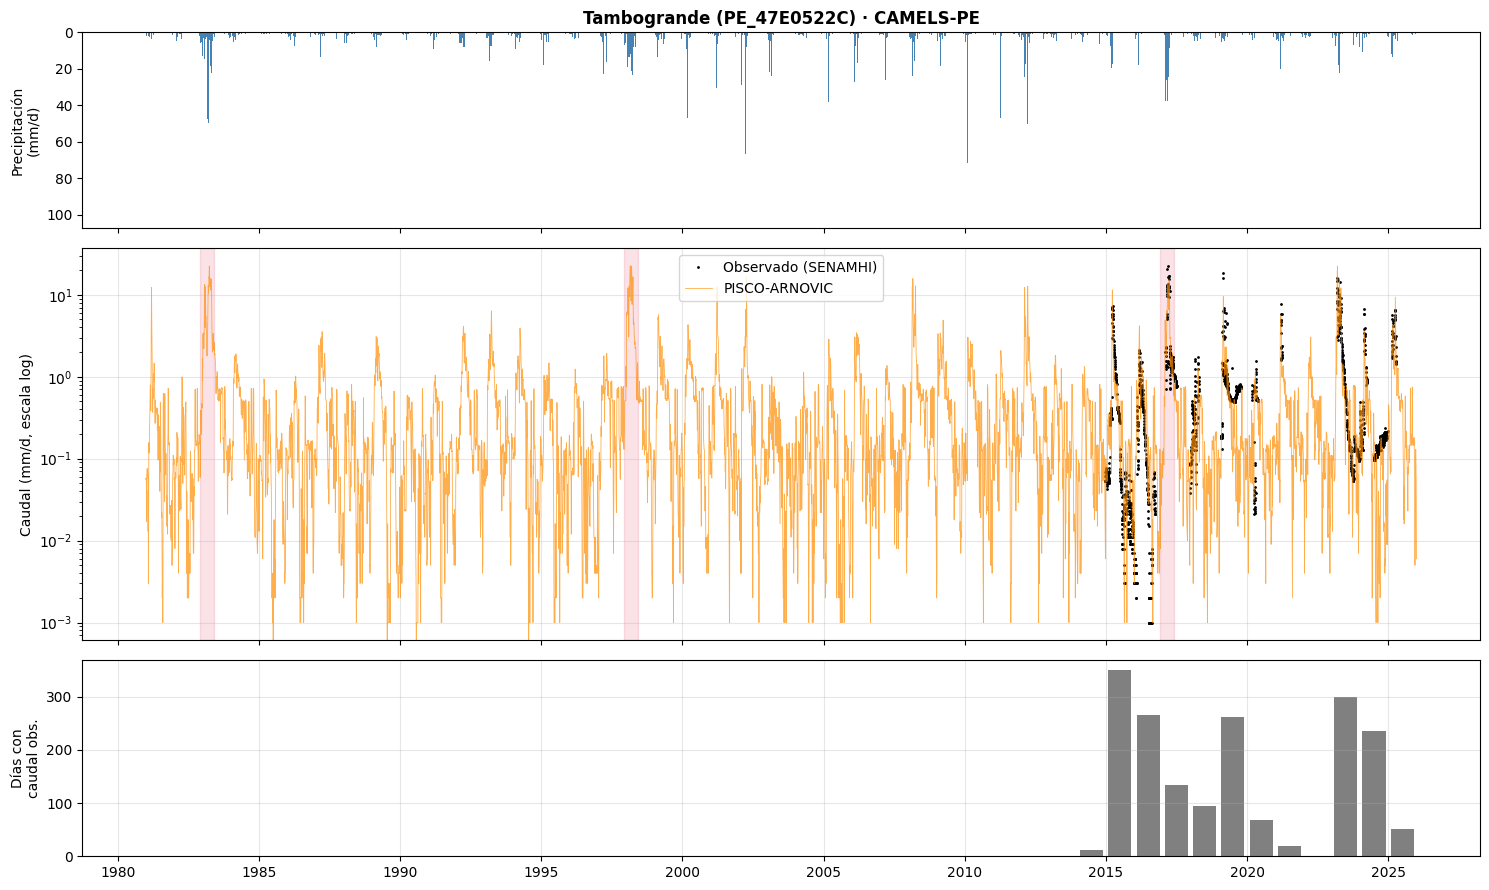

In [17]:
def leer_serie(ruta):
    cam = pd.read_csv(ruta, parse_dates=['date'], index_col='date').sort_index()
    return cam.select_dtypes(include=[np.number])        # ignora columnas de texto (p. ej. gauge_id)

ruta_serie = asegurar(f'{GAUGE}.csv', preferir=('time', 'serie'))
camels = leer_serie(ruta_serie)
obs = camels['flow_obs'].dropna()
print(f"Periodo: {camels.index.min().date()} a {camels.index.max().date()}  ({len(camels)} días)")
print(f"Días con caudal observado: {len(obs)} ({camels['flow_obs'].notna().mean():.0%})  |  primero: {obs.index.min().date()}  último: {obs.index.max().date()}")
print(f"Caudal observado (mm/d): mediana {obs.median():.3f} | P95 {obs.quantile(.95):.3f} | máximo {obs.max():.2f} el {obs.idxmax().date()} | días en cero: {(obs == 0).sum()}")
display(camels.describe().T.round(2))

fig, ejes = plt.subplots(3, 1, figsize=(15, 9), sharex=True, gridspec_kw={'height_ratios': [1, 2, 1]})
ejes[0].bar(camels.index, camels['prec'], width=1, color='steelblue'); ejes[0].invert_yaxis()
ejes[0].set_ylabel('Precipitación\n(mm/d)'); ejes[0].set_title(f'{NOMBRE_ESTACION.title()} ({GAUGE}) · CAMELS-PE', fontweight='bold')
ejes[1].plot(camels.index, camels['flow_obs'], 'k.', ms=2, label='Observado (SENAMHI)')
ejes[1].plot(camels.index, camels['flow_sim'], '-', color='darkorange', lw=0.6, alpha=0.7, label='PISCO-ARNOVIC')
ejes[1].set_yscale('log'); ejes[1].set_ylabel('Caudal (mm/d, escala log)'); ejes[1].legend(); ejes[1].grid(alpha=0.3)
for anio in (1983, 1998, 2017):                           # años Niño extremos para Piura
    ejes[1].axvspan(pd.Timestamp(f'{anio - 1}-12-01'), pd.Timestamp(f'{anio}-05-31'), color='crimson', alpha=0.12)
dias = camels['flow_obs'].groupby(camels.index.year).count()
ejes[2].bar(pd.to_datetime(dias.index.astype(str) + '-07-01'), dias.values, width=300, color='gray')
ejes[2].set_ylabel('Días con\ncaudal obs.'); ejes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 1.1 Periodos de entrenamiento, validación y prueba

La división es **cronológica** (nunca al azar): entrenamiento → validación (para el *early stopping*) → prueba. Usamos los periodos del Lab 9_3 para poder comparar con Huatiapa. **Pero** si en esta estación hay muy pocos días con caudal observado en algún periodo, el NSE no sería confiable; en ese caso el código propone periodos automáticos (60 % / 20 % / 20 % de los días observados, cortados en fin de año).

In [18]:
def contar_obs(cam, per):
    o = cam['flow_obs']
    dia = pd.Timedelta(days=1)
    return {'entrena': int(o[per['ini_entrena']:per['fin_entrena']].count()),
            'valida':  int(o[pd.Timestamp(per['fin_entrena']) + dia:per['fin_valida']].count()),
            'prueba':  int(o[pd.Timestamp(per['fin_valida']) + dia:per['fin_prueba']].count())}

def proponer_periodos(cam, fin_max=PERIODOS_LAB['fin_prueba']):
    o = cam['flow_obs'].loc[:fin_max].dropna()
    if len(o) < 1000:
        raise ValueError(f'Solo {len(o)} días con caudal observado hasta {fin_max}: la serie es muy corta para entrenar una LSTM.')
    a_ent = o.index[int(len(o) * 0.6)].year
    a_val = max(o.index[int(len(o) * 0.8)].year, a_ent + 1)
    ini = max(o.index[0], pd.Timestamp('1982-01-01'))                     # deja >1 año de meteorología previa para las ventanas
    return {'ini_entrena': str(ini.date()), 'fin_entrena': f'{a_ent}-12-31',
            'fin_valida': f'{a_val}-12-31', 'fin_prueba': fin_max}

def elegir_periodos(cam, verbose=True):
    per = dict(PERIODOS_LAB)
    n = contar_obs(cam, per)
    if all(n[k] >= MIN_DIAS_OBS[k] for k in n):
        if verbose: print(f'Periodos del Lab 9_3 (días con caudal observado: {n})')
        return per, 'lab'
    if verbose: print(f'Con los periodos del Lab 9_3 hay pocos días observados {n} (mínimos {MIN_DIAS_OBS}). Uso periodos automáticos.')
    per = proponer_periodos(cam)
    n2 = contar_obs(cam, per)
    if verbose: print(f'Periodos automáticos: {per} | días observados: {n2}')
    if verbose and any(n2[k] < MIN_DIAS_OBS[k] for k in n2):
        print('⚠️  Incluso así hay pocos días observados en algún periodo: interpreta el NSE con mucha cautela (y revisa si hay otra estación cercana con más datos).')
    return per, 'auto'

periodos, modo_periodos = elegir_periodos(camels)

Con los periodos del Lab 9_3 hay pocos días observados {'entrena': 0, 'valida': 362, 'prueba': 825} (mínimos {'entrena': 730, 'valida': 180, 'prueba': 365}). Uso periodos automáticos.
Periodos automáticos: {'ini_entrena': '2014-12-21', 'fin_entrena': '2017-12-31', 'fin_valida': '2019-12-31', 'fin_prueba': '2020-12-31'} | días observados: {'entrena': 762, 'valida': 356, 'prueba': 69}
⚠️  Incluso así hay pocos días observados en algún periodo: interpreta el NSE con mucha cautela (y revisa si hay otra estación cercana con más datos).


# 2. El pipeline como funciones

Todo lo del Lab 9_3 queda **parametrizado** (nada está "pegado" a Huatiapa):

| Función | Qué hace |
|---|---|
| `preparar` | recorta, normaliza la meteorología (solo con el periodo de entrenamiento) y transforma el caudal a log con un offset adaptado a la cuenca |
| `crear_ventanas` | tensores `(muestras, días, variables)`; el objetivo es el caudal observado de `t + horizonte` |
| `entrenar_ensamble` | entrena la misma red con varias semillas |
| `simulacion` (A1) | solo meteorología → caudal de hoy; baselines: **climatología** y **PISCO-ARNOVIC** |
| `pronostico` (A2) | meteorología + caudal reciente → caudal a H días; la LSTM predice el **cambio** Δ; baseline: **persistencia** |
| `correr_cuenca` | ejecuta todo para un `gauge_id` y devuelve un diccionario con resultados |

**Cambios respecto al Lab 9_3** (todos pensados para otra cuenca): offset del log automático, periodos validados, ensamble de semillas, climatología como línea base extra y revisión de huecos en la meteorología.

In [19]:
# ---------- métricas ----------
def nse(obs, sim):
    d = np.sum((obs - obs.mean()) ** 2)
    return np.nan if d == 0 else 1 - np.sum((obs - sim) ** 2) / d

def kge(obs, sim):
    if obs.std() == 0 or sim.std() == 0 or obs.mean() == 0:
        return np.nan
    r = np.corrcoef(obs, sim)[0, 1]
    return 1 - np.sqrt((r - 1) ** 2 + (sim.std() / obs.std() - 1) ** 2 + (sim.mean() / obs.mean() - 1) ** 2)

# ---------- preparación de datos ----------
def preparar(cam, per, eps_log=EPS_LOG):
    ini_df = pd.Timestamp(per['ini_entrena']) - pd.DateOffset(years=2)       # años extra para llenar las primeras ventanas
    df = cam.loc[ini_df:per['fin_prueba']].copy()
    vars_met = [v for v in VARS_MET if v in df.columns]
    if len(vars_met) < len(VARS_MET):
        print('Aviso: faltan variables', [v for v in VARS_MET if v not in df.columns], '→ se usan', vars_met)
    n_nan = int(df[vars_met].isna().sum().sum())
    if n_nan:
        print(f'Aviso: {n_nan} valores faltantes en la meteorología; se interpolan linealmente.')
        df[vars_met] = df[vars_met].interpolate(limit_direction='both')
    entrena = (df.index >= per['ini_entrena']) & (df.index <= per['fin_entrena'])

    X = df[vars_met].values.astype('float32')
    mu, sd = X[entrena].mean(0), X[entrena].std(0)
    sd[sd == 0] = 1
    X_n = (X - mu) / sd

    q_obs = df['flow_obs'].values
    if eps_log is None:                                                       # offset del log adaptado a la cuenca
        pos = q_obs[entrena & ~np.isnan(q_obs) & (q_obs > 0)]
        eps_log = float(np.clip(0.1 * np.median(pos), 0.001, 0.1)) if pos.size else 0.01
    q_log = np.log(q_obs + eps_log)
    q_media, q_desv = np.nanmean(q_log[entrena]), np.nanstd(q_log[entrena])
    q_n = (q_log - q_media) / q_desv

    relleno = df['flow_obs'].fillna(df['flow_sim']).ffill().bfill().values    # caudal "conocido": observado, o simulado si falta
    q_ent = (np.log(relleno + eps_log) - q_media) / q_desv
    bandera = df['flow_obs'].notna().values.astype('float32')                 # 1 = observado, 0 = relleno
    return dict(df=df, per=per, vars_met=vars_met, X_n=X_n, q_obs=q_obs, q_n=q_n, q_ent=q_ent,
                bandera=bandera, eps=eps_log, q_media=q_media, q_desv=q_desv)

def a_caudal(D, v):
    """De la escala normalizada-log de vuelta a mm/d"""
    return np.maximum(np.exp(np.asarray(v) * D['q_desv'] + D['q_media']) - D['eps'], 0)

def crear_ventanas(D, X, ventana, horizonte=0):
    """Ventanas que terminan en t; el objetivo es el caudal observado en t + horizonte."""
    df, per, q_obs = D['df'], D['per'], D['q_obs']
    t = np.arange(ventana - 1, len(X) - horizonte)
    ok = ~np.isnan(q_obs[t + horizonte]) & (df.index[t + horizonte] >= per['ini_entrena'])
    t = t[ok]
    Xw = np.stack([X[i - ventana + 1:i + 1] for i in t]).astype('float32')
    fechas = df.index[t + horizonte]
    periodos = {'entrena': (fechas <= per['fin_entrena']),
                'valida':  (fechas > per['fin_entrena']) & (fechas <= per['fin_valida']),
                'prueba':  (fechas > per['fin_valida'])}
    return Xw, t, fechas, periodos

# ---------- entrenamiento ----------
def entrenar(fabrica_capa, Xw, y, periodos, epocas, semilla):
    keras.utils.set_random_seed(semilla)
    modelo = keras.Sequential([keras.Input(shape=Xw.shape[1:]), fabrica_capa(), layers.Dropout(0.2), layers.Dense(1)])
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3), loss='mse')
    e, v = periodos['entrena'], periodos['valida']
    hist = modelo.fit(Xw[e], y[e], epochs=epocas, batch_size=128, validation_data=(Xw[v], y[v]),
                      callbacks=[keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True)], verbose=0)
    return modelo, len(hist.history['loss'])

def entrenar_ensamble(fabrica_capa, Xw, y, periodos, epocas, n, etiqueta):
    t0, modelos, ep = time.time(), [], []
    for s in range(n):
        m, e = entrenar(fabrica_capa, Xw, y, periodos, epocas, semilla=42 + s)
        modelos.append(m); ep.append(e)
    print(f'  {etiqueta:<12s} {n} semilla(s) | épocas {ep} | {time.time() - t0:5.1f} s')
    return modelos

def predecir(modelos, X):
    P = np.stack([m.predict(X, verbose=0).ravel() for m in modelos])
    return P.mean(0), P            # (ensamble, individuales)

def climatologia_doy(D):
    """Línea base: caudal medio observado por día del año en el periodo de entrenamiento."""
    df, per = D['df'], D['per']
    m = (df.index >= per['ini_entrena']) & (df.index <= per['fin_entrena'])
    s = df['flow_obs'][m].groupby(df.index[m].dayofyear).mean()
    return s.reindex(range(1, 367)).interpolate(limit_direction='both')

In [20]:
# ---------- A1: simulación lluvia–escorrentía ----------
def simulacion(D, ventana, n, epocas):
    Xs, ts, fechas, per_s = crear_ventanas(D, D['X_n'], ventana)
    ys = D['q_n'][ts].astype('float32')
    cuentas = {k: int(v.sum()) for k, v in per_s.items()}
    print(f'A1 · tensor {Xs.shape} → (muestras, días, variables) | muestras por periodo: {cuentas}')
    if min(cuentas.values()) < 30:
        raise ValueError('Algún periodo tiene menos de 30 muestras: revisa los periodos o la cobertura de caudal.')
    rnn = entrenar_ensamble(lambda: layers.SimpleRNN(32), Xs, ys, per_s, epocas, n, 'SimpleRNN')
    lstm = entrenar_ensamble(lambda: layers.LSTM(32), Xs, ys, per_s, epocas, n, 'LSTM')

    p = per_s['prueba']
    obs = D['q_obs'][ts][p]
    f = fechas[p]
    series = {'Climatología': climatologia_doy(D).loc[f.dayofyear].values,
              'PISCO-ARNOVIC': D['df']['flow_sim'].values[ts][p]}
    indiv = {}
    for nombre, modelos in [('RNN simple', rnn), ('LSTM', lstm)]:
        ens, P = predecir(modelos, Xs[p])
        series[nombre] = a_caudal(D, ens)
        indiv[nombre] = [nse(obs, a_caudal(D, P[i])) for i in range(len(P))]
    filas = {}
    for nombre, pred in series.items():
        ind = indiv.get(nombre)
        filas[nombre] = {'NSE': nse(obs, pred), 'KGE': kge(obs, pred),
                         'NSE por semilla (media)': np.mean(ind) if ind else np.nan,
                         'NSE por semilla (desv.)': np.std(ind) if ind else np.nan}
    return {'tabla': pd.DataFrame(filas).T.round(3), 'fechas': f, 'obs': obs, 'series': series, 'muestras': cuentas}

# ---------- A2: pronóstico con asimilación del caudal observado ----------
def pronostico(D, ventana, horizontes, n, epocas):
    X = np.column_stack([D['X_n'], D['q_ent'], D['bandera']]).astype('float32')
    out = {}
    for H in horizontes:
        Xp, tp, fechas, per_p = crear_ventanas(D, X, ventana, horizonte=H)
        base = D['q_ent'][tp]                                       # último caudal conocido (normalizado-log)
        yp = (D['q_n'][tp + H] - base).astype('float32')            # objetivo: el CAMBIO hasta t+H
        print(f'Horizonte {H} d · muestras por periodo: { {k: int(v.sum()) for k, v in per_p.items()} }')
        modelos = entrenar_ensamble(lambda: layers.LSTM(32), Xp, yp, per_p, epocas, n, f'LSTM H={H}')
        p = per_p['prueba']
        ens, P = predecir(modelos, Xp[p])
        obs = D['q_obs'][tp + H][p]
        out[H] = {'fechas': fechas[p], 'obs': obs,
                  'LSTM': a_caudal(D, ens + base[p]),
                  'Persistencia': a_caudal(D, base[p]),
                  'PISCO-ARNOVIC': D['df']['flow_sim'].values[tp + H][p],
                  'nse_semillas': [nse(obs, a_caudal(D, P[i] + base[p])) for i in range(len(P))]}
    filas = {H: {'NSE LSTM': nse(r['obs'], r['LSTM']), 'NSE Persistencia': nse(r['obs'], r['Persistencia']),
                 'NSE ARNOVIC': nse(r['obs'], r['PISCO-ARNOVIC']),
                 'KGE LSTM': kge(r['obs'], r['LSTM']), 'KGE Persistencia': kge(r['obs'], r['Persistencia']),
                 'NSE LSTM por semilla (desv.)': np.std(r['nse_semillas'])} for H, r in out.items()}
    return {'tabla': pd.DataFrame(filas).T.round(3), 'por_horizonte': out}

# ---------- todo junto ----------
def correr_cuenca(gauge_id, ventana_sim=VENTANA_SIM, ventana_pron=VENTANA_PRON, horizontes=HORIZONTES,
                  n_semillas=N_SEMILLAS, epocas=EPOCAS):
    print(f'===== Cuenca {gauge_id} =====')
    cam = leer_serie(asegurar(f'{gauge_id}.csv', preferir=('time', 'serie')))
    per, modo = elegir_periodos(cam)
    D = preparar(cam, per)
    print(f"Offset del log (eps) = {D['eps']:.4f} mm/d | variables de entrada: {D['vars_met']}")
    A1 = simulacion(D, ventana_sim, n_semillas, epocas)
    A2 = pronostico(D, ventana_pron, horizontes, n_semillas, epocas)
    return {'gauge_id': gauge_id, 'camels': cam, 'periodos': per, 'modo_periodos': modo, 'D': D, 'A1': A1, 'A2': A2}

def tabla_comparativa(resultados):
    """resultados = {'nombre cuenca': salida de correr_cuenca, ...}  →  NSE de la prueba lado a lado"""
    filas = {}
    for c, r in resultados.items():
        for m in ['Climatología', 'PISCO-ARNOVIC', 'RNN simple', 'LSTM']:
            filas.setdefault(f'A1 · {m}', {})[c] = r['A1']['tabla'].loc[m, 'NSE']
        for H, fila in r['A2']['tabla'].iterrows():
            filas.setdefault(f'A2 · H={H} d · LSTM', {})[c] = fila['NSE LSTM']
            filas.setdefault(f'A2 · H={H} d · Persistencia', {})[c] = fila['NSE Persistencia']
    return pd.DataFrame(filas).T.round(3)

# 3. Correr el modelo en Tambogrande

Entrena RNN y LSTM (A1) y la LSTM de pronóstico (A2) con `N_SEMILLAS` semillas. Mientras corre verás cuántas muestras hay en cada periodo y cuántas épocas usó cada red (el *early stopping* corta cuando la validación deja de mejorar).

In [21]:
res_tg = correr_cuenca(GAUGE)

===== Cuenca PE_47E0522C =====
Con los periodos del Lab 9_3 hay pocos días observados {'entrena': 0, 'valida': 362, 'prueba': 825} (mínimos {'entrena': 730, 'valida': 180, 'prueba': 365}). Uso periodos automáticos.
Periodos automáticos: {'ini_entrena': '2014-12-21', 'fin_entrena': '2017-12-31', 'fin_valida': '2019-12-31', 'fin_prueba': '2020-12-31'} | días observados: {'entrena': 762, 'valida': 356, 'prueba': 69}
⚠️  Incluso así hay pocos días observados en algún periodo: interpreta el NSE con mucha cautela (y revisa si hay otra estación cercana con más datos).
Offset del log (eps) = 0.0095 mm/d | variables de entrada: ['prec', 'tmean', 'tmax', 'tmin', 'srad', 'vprp']
A1 · tensor (1187, 180, 6) → (muestras, días, variables) | muestras por periodo: {'entrena': 762, 'valida': 356, 'prueba': 69}
  SimpleRNN    3 semilla(s) | épocas [7, 36, 7] |  21.4 s
  LSTM         3 semilla(s) | épocas [7, 8, 7] |  22.4 s


Horizonte 1 d · muestras por periodo: {'entrena': 762, 'valida': 356, 'prueba': 69}
  LSTM H=1     3 semilla(s) | épocas [40, 40, 34] |  56.1 s
Horizonte 3 d · muestras por periodo: {'entrena': 762, 'valida': 356, 'prueba': 69}
  LSTM H=3     3 semilla(s) | épocas [11, 17, 22] |  28.8 s
Horizonte 7 d · muestras por periodo: {'entrena': 762, 'valida': 356, 'prueba': 69}
  LSTM H=7     3 semilla(s) | épocas [12, 16, 12] |  24.0 s


## 3.1 Resultados A1 · Simulación solo con meteorología

Periodo de prueba: 2020–2020  (69 días con caudal observado)



,NSE,KGE,NSE por semilla (media),NSE por semilla (desv.)
Climatología,-45.160,-4.345,NaN,NaN
PISCO-ARNOVIC,-1.311,-0.367,NaN,NaN
RNN simple,-1.041,-0.559,-1.994,0.562
LSTM,-0.781,-0.958,-0.743,0.310


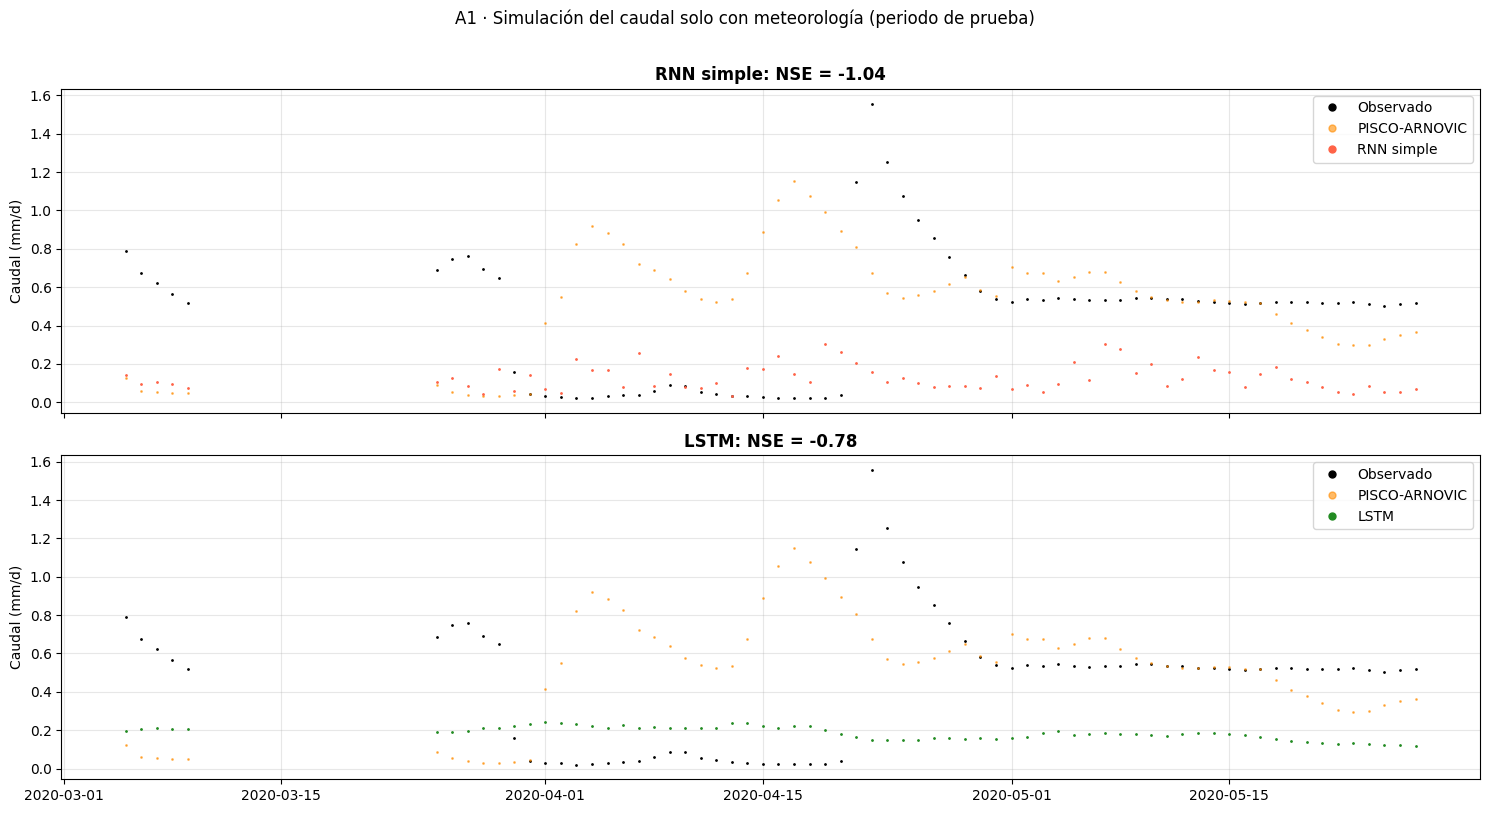

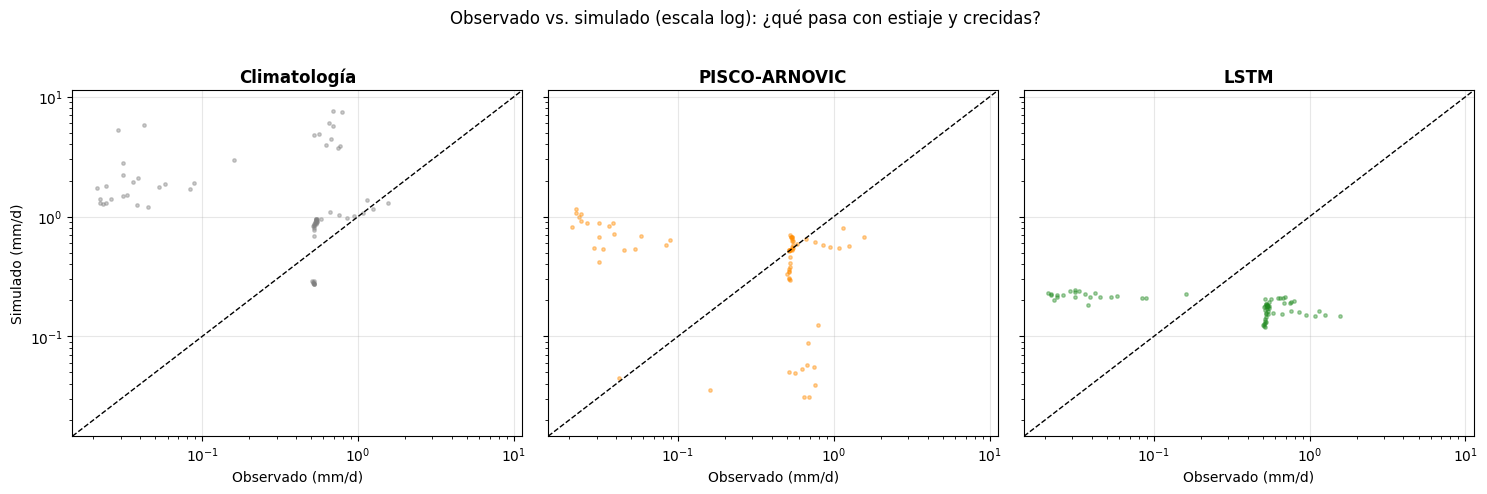

In [22]:
a = res_tg['A1']
per = res_tg['periodos']
print(f"Periodo de prueba: {int(per['fin_valida'][:4]) + 1}–{per['fin_prueba'][:4]}  ({len(a['obs'])} días con caudal observado)\n")
display(a['tabla'])

def graficar_A1(a):
    fig, ejes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
    for ax, clave, color in [(ejes[0], 'RNN simple', 'tomato'), (ejes[1], 'LSTM', 'forestgreen')]:
        ax.plot(a['fechas'], a['obs'], 'k.', ms=2, label='Observado')
        ax.plot(a['fechas'], a['series']['PISCO-ARNOVIC'], '.', color='darkorange', ms=2, alpha=0.6, label='PISCO-ARNOVIC')
        ax.plot(a['fechas'], a['series'][clave], '.', color=color, ms=2, label=clave)
        ax.set_ylabel('Caudal (mm/d)'); ax.grid(alpha=0.3); ax.legend(markerscale=5)
        ax.set_title(f"{clave}: NSE = {a['tabla'].loc[clave, 'NSE']:.2f}", fontweight='bold')
    plt.suptitle('A1 · Simulación del caudal solo con meteorología (periodo de prueba)', y=1.01)
    plt.tight_layout(); plt.show()

    # ¿cómo se comportan los caudales bajos y los picos? (log–log, línea 1:1)
    fig, ejes = plt.subplots(1, 3, figsize=(15, 4.8), sharex=True, sharey=True)
    todas = np.concatenate([a['obs']] + [a['series'][k] for k in ['Climatología', 'PISCO-ARNOVIC', 'LSTM']])
    pos = todas[todas > 0]
    lo, hi = max(pos.min() * 0.7, 1e-3), pos.max() * 1.5                    # límites comunes (los ceros se dibujan en el límite inferior)
    for ax, clave, color in [(ejes[0], 'Climatología', 'gray'), (ejes[1], 'PISCO-ARNOVIC', 'darkorange'), (ejes[2], 'LSTM', 'forestgreen')]:
        ax.scatter(np.maximum(a['obs'], lo), np.maximum(a['series'][clave], lo), s=6, alpha=0.4, color=color)
        ax.plot([lo, hi], [lo, hi], 'k--', lw=1); ax.set_xscale('log'); ax.set_yscale('log'); ax.grid(alpha=0.3)
        ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
        ax.set_title(clave, fontweight='bold'); ax.set_xlabel('Observado (mm/d)')
    ejes[0].set_ylabel('Simulado (mm/d)')
    plt.suptitle('Observado vs. simulado (escala log): ¿qué pasa con estiaje y crecidas?', y=1.02)
    plt.tight_layout(); plt.show()

graficar_A1(a)

## 3.2 Resultados A2 · Pronóstico a 1, 3 y 7 días

,NSE LSTM,NSE Persistencia,NSE ARNOVIC,KGE LSTM,KGE Persistencia,NSE LSTM por semilla (desv.)
1,0.685,0.677,-1.311,0.790,0.839,0.032
3,-0.071,-0.118,-1.311,0.399,0.448,0.256
7,-0.814,-0.885,-1.311,-0.006,0.062,0.438


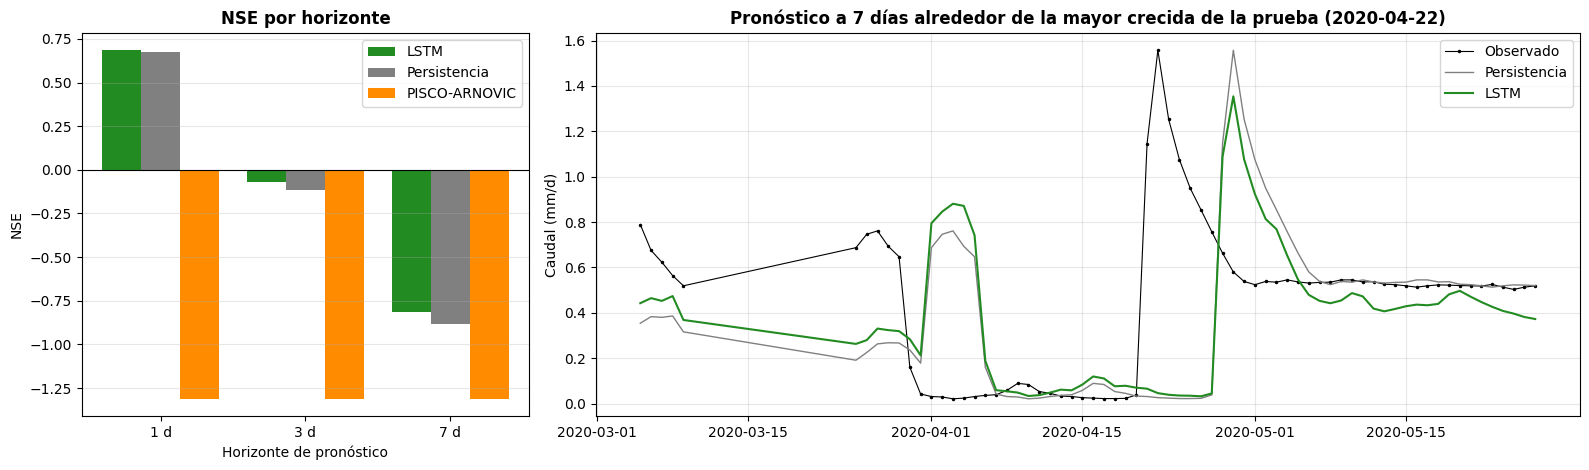

In [23]:
display(res_tg['A2']['tabla'])

def graficar_A2(r2):
    por_h = r2['por_horizonte']
    horizontes = list(por_h)
    fig, ejes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={'width_ratios': [1, 2.2]})
    ancho = 0.27
    for k, (modelo, color) in enumerate([('LSTM', 'forestgreen'), ('Persistencia', 'gray'), ('PISCO-ARNOVIC', 'darkorange')]):
        vals = [nse(por_h[H]['obs'], por_h[H][modelo]) for H in horizontes]
        ejes[0].bar(np.arange(len(horizontes)) + (k - 1) * ancho, vals, ancho, color=color, label=modelo)
    ejes[0].axhline(0, color='k', lw=0.8)
    ejes[0].set_xticks(range(len(horizontes))); ejes[0].set_xticklabels([f'{H} d' for H in horizontes])
    ejes[0].set_xlabel('Horizonte de pronóstico'); ejes[0].set_ylabel('NSE')
    ejes[0].set_title('NSE por horizonte', fontweight='bold'); ejes[0].legend(); ejes[0].grid(axis='y', alpha=0.3)

    H = horizontes[-1]; r = por_h[H]
    pico = r['fechas'][int(np.argmax(r['obs']))]                           # alrededor de la mayor crecida observada en la prueba
    tramo = (r['fechas'] >= pico - pd.Timedelta(days=75)) & (r['fechas'] <= pico + pd.Timedelta(days=75))
    ejes[1].plot(r['fechas'][tramo], r['obs'][tramo], 'k.-', ms=3, lw=0.8, label='Observado')
    ejes[1].plot(r['fechas'][tramo], r['Persistencia'][tramo], '-', color='gray', lw=1, label='Persistencia')
    ejes[1].plot(r['fechas'][tramo], r['LSTM'][tramo], '-', color='forestgreen', lw=1.5, label='LSTM')
    ejes[1].set_ylabel('Caudal (mm/d)'); ejes[1].legend(); ejes[1].grid(alpha=0.3)
    ejes[1].set_title(f'Pronóstico a {H} días alrededor de la mayor crecida de la prueba ({pico.date()})', fontweight='bold')
    plt.tight_layout(); plt.show()

graficar_A2(res_tg['A2'])

## 3.3 ¿Funciona igual que en Huatiapa?

Valores de referencia tomados de **tu Lab 9_3** (una sola ejecución, 1 semilla; varían entre ejecuciones). Para una comparación exacta con el mismo código y las mismas semillas, activa `COMPARAR_CON_HUATIAPA = True` en la configuración.

In [24]:
REF_HUATIAPA = {  # NSE en la prueba 2016–2020, salidas del Lab 9_3
    'A1 · PISCO-ARNOVIC': -0.295, 'A1 · RNN simple': 0.356, 'A1 · LSTM': 0.407,
    'A2 · H=1 d · LSTM': 0.921, 'A2 · H=1 d · Persistencia': 0.917,
    'A2 · H=3 d · LSTM': 0.718, 'A2 · H=3 d · Persistencia': 0.670,
    'A2 · H=7 d · LSTM': 0.414, 'A2 · H=7 d · Persistencia': 0.348}

tabla = tabla_comparativa({f'{NOMBRE_ESTACION.title()} (esta corrida)': res_tg})
tabla.insert(0, 'Huatiapa (Lab 9_3)', pd.Series(REF_HUATIAPA))
display(tabla)

def veredicto(res):
    t, T = res['A1']['tabla'], res['A2']['tabla']
    out = []
    l, ar, rn, cl = (t.loc[k, 'NSE'] for k in ['LSTM', 'PISCO-ARNOVIC', 'RNN simple', 'Climatología'])
    out.append(f"A1 · La LSTM {'SUPERA' if l > ar else 'NO supera'} a PISCO-ARNOVIC (NSE {l:.2f} vs {ar:.2f}) y {'supera' if l > cl else 'NO supera'} a la climatología ({cl:.2f}).")
    out.append(f"A1 · La LSTM {'supera' if l > rn else 'NO supera'} a la RNN simple ({l:.2f} vs {rn:.2f}); desviación entre semillas de la LSTM: {t.loc['LSTM', 'NSE por semilla (desv.)']:.2f}.")
    for H, f in T.iterrows():
        ok = f['NSE LSTM'] > f['NSE Persistencia']
        out.append(f"A2 · H={H} d: la LSTM {'SUPERA' if ok else 'NO supera'} a la persistencia (NSE {f['NSE LSTM']:.2f} vs {f['NSE Persistencia']:.2f}).")
    return '\n'.join(out)

print('\n' + veredicto(res_tg))

,Huatiapa (Lab 9_3),Tambogrande (esta corrida)
A1 · Climatología,NaN,-45.160
A1 · PISCO-ARNOVIC,-0.295,-1.311
A1 · RNN simple,0.356,-1.041
A1 · LSTM,0.407,-0.781
A2 · H=1 d · LSTM,0.921,0.685
A2 · H=1 d · Persistencia,0.917,0.677
A2 · H=3 d · LSTM,0.718,-0.071
A2 · H=3 d · Persistencia,0.670,-0.118
A2 · H=7 d · LSTM,0.414,-0.814
A2 · H=7 d · Persistencia,0.348,-0.885



A1 · La LSTM SUPERA a PISCO-ARNOVIC (NSE -0.78 vs -1.31) y supera a la climatología (-45.16).
A1 · La LSTM supera a la RNN simple (-0.78 vs -1.04); desviación entre semillas de la LSTM: 0.31.
A2 · H=1 d: la LSTM SUPERA a la persistencia (NSE 0.69 vs 0.68).
A2 · H=3 d: la LSTM SUPERA a la persistencia (NSE -0.07 vs -0.12).
A2 · H=7 d: la LSTM SUPERA a la persistencia (NSE -0.81 vs -0.89).


# 4. Extras opcionales

* **Sensibilidad a la ventana** (`CORRER_SENSIBILIDAD = True`): ¿cuánta memoria necesita esta cuenca? Una cuenca de respuesta rápida debería saturar con ventanas cortas; el Majes necesitaba más.
* **Comparación exacta con Huatiapa** (`COMPARAR_CON_HUATIAPA = True`): vuelve a correr Huatiapa (`PE_204617`) con este mismo código y semillas.
* **Exportar para tu proyecto**: caudal mensual y por temporada dic–may, con control de completitud.

In [25]:
if CORRER_SENSIBILIDAD:
    D = res_tg['D']
    filas = {}
    for v in [30, 90, 180, 365]:
        Xs, ts, fechas, per_s = crear_ventanas(D, D['X_n'], v)
        ys = D['q_n'][ts].astype('float32')
        modelos = entrenar_ensamble(lambda: layers.LSTM(32), Xs, ys, per_s, EPOCAS, 1, f'LSTM v={v}')
        p = per_s['prueba']
        pred = a_caudal(D, predecir(modelos, Xs[p])[0]); obs = D['q_obs'][ts][p]
        filas[v] = {'NSE': nse(obs, pred), 'KGE': kge(obs, pred), 'muestras de prueba': int(p.sum())}
    sens = pd.DataFrame(filas).T.rename_axis('ventana (días)')
    sens['muestras de prueba'] = sens['muestras de prueba'].astype(int)
    display(sens.round(3))
else:
    print('Sensibilidad omitida (CORRER_SENSIBILIDAD = False).')

Sensibilidad omitida (CORRER_SENSIBILIDAD = False).


In [ ]:
if COMPARAR_CON_HUATIAPA:
    res_hua = correr_cuenca('PE_204617')
    display(tabla_comparativa({'Tambogrande': res_tg, 'Huatiapa': res_hua}))
else:
    print('Comparación exacta omitida (COMPARAR_CON_HUATIAPA = False).')

In [26]:
def exportar_proyecto(cam, nombre, min_frac=MIN_FRAC_EXPORT):
    """Caudal mensual y por temporada dic–may (año de la temporada = año en que termina), solo si hay >= min_frac de días observados."""
    d = cam[['prec', 'flow_obs', 'flow_sim']].copy()
    g = d.resample('MS')
    mens = pd.DataFrame({'prec_mm_mes': g['prec'].sum(), 'caudal_obs_mm_d': g['flow_obs'].mean(),
                         'caudal_sim_mm_d': g['flow_sim'].mean(), 'dias_obs': g['flow_obs'].count(), 'dias_mes': g['flow_obs'].size()})
    mens.loc[mens['dias_obs'] < min_frac * mens['dias_mes'], 'caudal_obs_mm_d'] = np.nan

    d['temporada'] = d.index.year + (d.index.month == 12)
    d = d[d.index.month.isin([12, 1, 2, 3, 4, 5])]
    gt = d.groupby('temporada')
    temp = pd.DataFrame({'prec_total_mm': gt['prec'].sum(), 'caudal_medio_mm_d': gt['flow_obs'].mean(),
                         'caudal_max_mm_d': gt['flow_obs'].max(), 'dias_obs': gt['flow_obs'].count(), 'dias_temporada': gt['flow_obs'].size()})
    mala = (temp['dias_obs'] < min_frac * temp['dias_temporada']) | (temp['dias_temporada'] < 181)   # <181 días = temporada incompleta (faltan meses)
    temp.loc[mala, ['caudal_medio_mm_d', 'caudal_max_mm_d']] = np.nan
    mens.to_csv(f'{nombre}_caudal_mensual.csv'); temp.to_csv(f'{nombre}_caudal_temporada_dic_may.csv')
    return mens, temp

if EXPORTAR_PARA_PROYECTO:
    mens, temp = exportar_proyecto(camels, f'{GAUGE}_{NOMBRE_ESTACION.lower()}')
    util = temp.dropna(subset=['caudal_medio_mm_d'])
    print(f'Temporadas dic–may completas con >= {MIN_FRAC_EXPORT:.0%} de días observados: {len(util)} de {len(temp)}')
    print('Años de esas temporadas:', list(util.index))
    display(util.round(2).tail(15))
    print('\nArchivos creados:', [f for f in os.listdir('.') if f.startswith(GAUGE) and f.endswith('.csv')])
    print('Para m³/s: Q(m³/s) = caudal(mm/d) × área(km²) / 86.4   (el área está en los atributos topográficos de CAMELS-PE)')
    try:
        from google.colab import files
        for f in [f for f in os.listdir('.') if f.startswith(GAUGE) and f.endswith('.csv')]:
            files.download(f)
    except ImportError:
        pass

Temporadas dic–may completas con >= 80% de días observados: 2 de 46
Años de esas temporadas: [2015, 2016]


,prec_total_mm,caudal_medio_mm_d,caudal_max_mm_d,dias_obs,dias_temporada
temporada,,,,,
2015,543.74,1.15,7.33,162,182
2016,427.45,0.37,2.13,182,183



Archivos creados: ['PE_47E0522C_tambogrande_caudal_mensual.csv', 'PE_47E0522C_tambogrande_caudal_temporada_dic_may.csv']
Para m³/s: Q(m³/s) = caudal(mm/d) × área(km²) / 86.4   (el área está en los atributos topográficos de CAMELS-PE)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 5. Q's

---



---



analisis:

1. **¿Se repite el resultado de Huatiapa?** ¿La LSTM supera a PISCO-ARNOVIC y a la climatología en A1? ¿Y a la persistencia en A2 (1, 3 y 7 días)? Si algo cambia, ¿a qué lo atribuyes: calidad del forzante (PISCOp), regulación del río, régimen de crecidas?
2. **Cobertura y confianza:** ¿cuántos días con caudal observado hay en el periodo de prueba? ¿Usó el código periodos del Lab o automáticos? ¿Cuánto varía el NSE entre semillas?
3. **Picos vs. estiaje:** mira el gráfico log–log. ¿La LSTM acierta los caudales bajos y las crecidas por igual? ¿Qué le pasa a la mayor crecida del periodo de prueba?
4. **Memoria de la cuenca** (si activaste la sensibilidad): ¿qué ventana basta? Compárala con la del Majes.
5. **Conexión con tu proyecto ENSO–Piura:** ¿cuántas temporadas dic–may tienen caudal observado utilizable? ¿Cubren 1983, 1998 o 2017? Eso decide qué hipótesis (H1, H2, H3) puedes evaluar con caudal.

### Limitaciones a mencionar
* Una sola cuenca y un periodo de prueba corto: el NSE depende mucho de pocos eventos extremos.
* PISCO-ARNOVIC es un modelo regional sin calibración local fina; la comparación mide "qué tan bien lo hace cada enfoque aquí", no cuál es mejor en general.
* El caudal observado puede estar afectado por derivaciones y embalses que no están en las entradas del modelo.
* La temperatura (PISCOt) termina en 2020, lo que fija el final del periodo de prueba.

**Cita del dataset:** Llauca, H., Montesinos-Caceres, C., Gutierrez-Reynaga, M., & Lavado-Casimiro, W. (2026). *CAMELS-PE: Catchment Attributes and Meteorology for Large-sample Studies in Peru* (v1.0.1). Zenodo. https://doi.org/10.5281/zenodo.21195425